# Figure 4 — Identifiability and noise robustness

Reference: `figures/output/figure4.pdf`

**a** Seed sweep design: each acquisition optimized 20 times with different random initializations, all converging to the same recovered OAC map. **b** Initialization range sweep across 10 conditions × 5 seeds. **c** Identifiability summary table for all 10 acquisitions, reporting per-acquisition seed CoV (across 20 seeds) and init CoV (across 7 stable initialization ranges). **d** Recovered tissue μ across the 10 initialization ranges for all acquisitions (top), with deviation from each acquisition's mean (bottom). **e** Noise robustness design: Gaussian noise injected at controlled SNRs. **f** Noise robustness summary table at six SNR levels (Original, 16, 12, 8, 4, 0 dB). **g** Per-acquisition |Δμ|, R², and σ_μ versus SNR for all 10 phantoms.

Data: `experiments/identifiability_study.py` (panels a–d) and `experiments/robustness_study.py` (panels e–g). Cached CSVs in `figures/data/`.

In [1]:
%matplotlib inline
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle

REPO_ROOT = os.path.abspath('..')
DATA_DIR  = os.path.join(REPO_ROOT, 'figures', 'data', 'figure4_identifiability_robustness')
PAPER_DIR = os.path.join(REPO_ROOT, 'figures', 'output')
os.makedirs(PAPER_DIR, exist_ok=True)

sys.path.insert(0, REPO_ROOT)

assert os.path.isdir(DATA_DIR), f'Data dir not found: {DATA_DIR}'
print('Files:', sorted(os.listdir(DATA_DIR)))

# ── Style constants ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'font.size': 8.75,
    'axes.titlesize': 10,
    'axes.labelsize': 8.75,
    'xtick.labelsize': 7.5,
    'ytick.labelsize': 7.5,
    'figure.dpi': 120,
})

CARTOON_PHANTOM = 'IL_5.0pct_rep1'
MU_FINAL_NPY = os.path.join(DATA_DIR, 'phantom_mu', f'{CARTOON_PHANTOM}_mu_final_mm.npy')
MU_INIT_NPY  = os.path.join(DATA_DIR, 'phantom_mu', f'{CARTOON_PHANTOM}_mu_init_mm.npy')
PHASE2_INIT_CSV = os.path.join(DATA_DIR, 'phase2_init_range_results.csv')

CONC_COLORS = {1.0:'#1f77b4', 1.5:'#ff7f0e', 2.0:'#2ca02c', 3.0:'#d62728', 5.0:'#9467bd'}
INIT_ORDER  = ['0_3','1_1','3_7','5_5','0_10','0_20','7_15','informed','10_10','15_15']
INIT_LABELS = {'0_3':'[0,3]','3_7':'[3,7]','7_15':'[7,15]','0_10':'[0,10]','0_20':'[0,20]',
               '1_1':'[1,1]','5_5':'[5,5]','10_10':'[10,10]','15_15':'[15,15]','informed':'Informed'}

# ── Load data ────────────────────────────────────────────────────────────────
mu_final_full = np.load(MU_FINAL_NPY)
mu_init_full  = np.load(MU_INIT_NPY)
ROW_START, ROW_END = 50, 400
mu_final_crop = mu_final_full[ROW_START:ROW_END, :]
mu_init_crop  = mu_init_full[ROW_START:ROW_END, :]

df_init  = pd.read_csv(PHASE2_INIT_CSV)

print(f'mu_final_crop shape: {mu_final_crop.shape}')
print(f'Init sweep:  {df_init.shape}')

Files: ['panel_ab_notitle.jpg', 'panel_e_notitle.jpg', 'per_acquisition_noise_curves.csv', 'phantom_mu', 'phase2_init_range_results.csv', 'tableB_physical_by_snr.csv']
mu_final_crop shape: (350, 500)
Init sweep:  (500, 7)


panel_ab: (2905, 3501, 3)
panel_c : (1322, 2757, 3)
subfig1_img: (3000, 9991, 3)


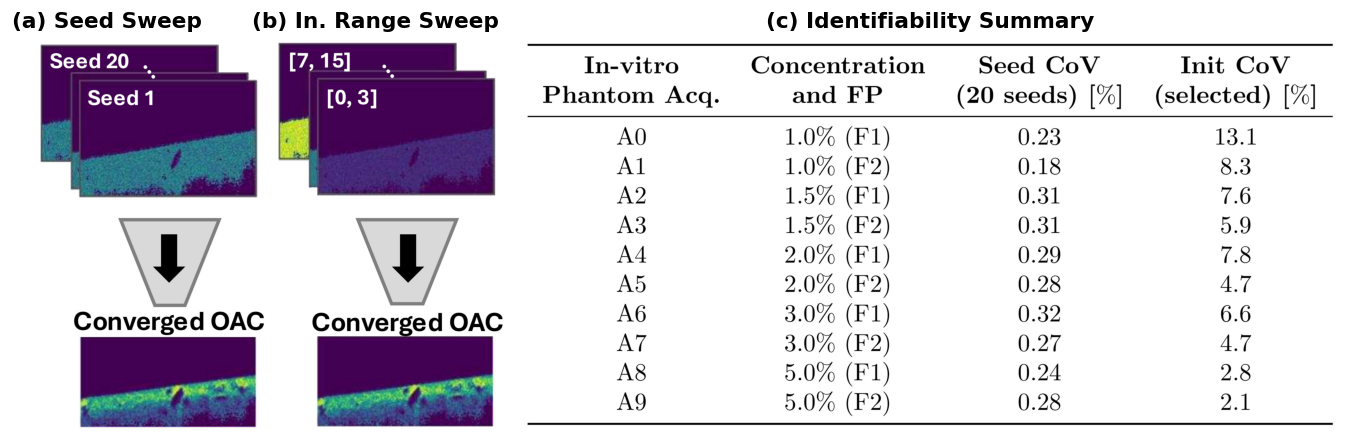

Subfigure 1 built (in-memory: (1078, 3346, 3))


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# Subfigure 1: (a) Seed Sweep, (b) In. Range Sweep — pre-rendered design diagram
#              (c) Identifiability Summary — built in-notebook from LaTeX
# ══════════════════════════════════════════════════════════════════════════════
from PIL import Image as _PILImage
import subprocess as _sp_sub
import tempfile as _tmpmod

_panel_dir = os.path.join(REPO_ROOT, 'figures', 'data', 'figure4_identifiability_robustness')
img_ab = np.array(_PILImage.open(os.path.join(_panel_dir, 'panel_ab_notitle.jpg')))

# ── Style constants (shared across all cells) ────────────────────────────────
PANEL_FS  = 13
LABEL_FS  = 11
TICK_FS   = 9.5
LEGEND_FS = 8
CONC_COLORS = {1.0:'#1f77b4', 1.5:'#ff7f0e', 2.0:'#2ca02c', 3.0:'#d62728', 5.0:'#9467bd'}

# ── Helper: resize image to target pixel height, preserving aspect ratio ─────
def _resize_to_height(arr, target_h):
    im = _PILImage.fromarray(arr)
    w_new = int(im.width * target_h / im.height)
    return np.array(im.resize((w_new, target_h), _PILImage.LANCZOS))

# ── Helper: horizontally concatenate images at matched height with gap ────────
def _hstack_matched(images, gap_px=100, target_h=None):
    if target_h is None:
        target_h = max(im.shape[0] for im in images)
    resized = [_resize_to_height(im, target_h) for im in images]
    gap = np.full((target_h, gap_px, 3), 255, dtype=np.uint8)
    parts = []
    for i, r in enumerate(resized):
        if i > 0:
            parts.append(gap)
        parts.append(r)
    return np.concatenate(parts, axis=1)

# ── Helper: compile LaTeX table to numpy array ───────────────────────────────
def _latex_table_to_img(latex_body, dpi=600):
    """Compile a LaTeX tabular body to a cropped numpy RGB array.

    Requires `pdflatex` on PATH and `PyMuPDF` (`fitz`) for rasterization.
    """
    import fitz  # PyMuPDF
    tex = (r'\documentclass[border=2pt]{standalone}' '\n'
           r'\usepackage{booktabs,amsmath}' '\n'
           r'\begin{document}' '\n'
           + latex_body + '\n'
           r'\end{document}')
    with _tmpmod.TemporaryDirectory() as tmpdir:
        tex_path = os.path.join(tmpdir, 'table.tex')
        pdf_path = os.path.join(tmpdir, 'table.pdf')
        with open(tex_path, 'w') as f:
            f.write(tex)
        _sp_sub.run(['pdflatex', '-interaction=nonstopmode',
                     f'-output-directory={tmpdir}', tex_path],
                    capture_output=True, check=True)
        doc = fitz.open(pdf_path)
        pix = doc[0].get_pixmap(dpi=dpi, alpha=False)
        arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    return arr

# ══════════════════════════════════════════════════════════════════════════════
# EDITABLE TABLE DATA — Panel (c) Identifiability Summary
# Source: figures/data/phase1_seed_sweep_results.csv + phase2_init_range_results.csv
# ══════════════════════════════════════════════════════════════════════════════
table_c_rows = [
    ('A0', r'1.0\% (F1)', r'0.23', r'13.1'),
    ('A1', r'1.0\% (F2)', r'0.18', r'8.3'),
    ('A2', r'1.5\% (F1)', r'0.31', r'7.6'),
    ('A3', r'1.5\% (F2)', r'0.31', r'5.9'),
    ('A4', r'2.0\% (F1)', r'0.29', r'7.8'),
    ('A5', r'2.0\% (F2)', r'0.28', r'4.7'),
    ('A6', r'3.0\% (F1)', r'0.32', r'6.6'),
    ('A7', r'3.0\% (F2)', r'0.27', r'4.7'),
    ('A8', r'5.0\% (F1)', r'0.24', r'2.8'),
    ('A9', r'5.0\% (F2)', r'0.28', r'2.1'),
]

_rows_c = ' \\\\\n'.join([' & '.join(row) for row in table_c_rows])
latex_c = (r'\begin{tabular}{c c c c}' '\n'
           r'\toprule' '\n'
           r'\textbf{In-vitro} & \textbf{Concentration} & \textbf{Seed CoV} & \textbf{Init CoV} \\' '\n'
           r'\textbf{Phantom Acq.} & \textbf{and FP} & \textbf{(20 seeds) [$\%$]} & \textbf{(selected) [$\%$]} \\' '\n'
           r'\midrule' '\n'
           + _rows_c + r' \\' '\n'
           r'\bottomrule' '\n'
           r'\end{tabular}')

img_c = _latex_table_to_img(latex_c)

print(f'panel_ab: {img_ab.shape}')
print(f'panel_c : {img_c.shape}')

# ── Build subfigure 1: (a/b) + (c) as a single image ────────────────────────
TARGET_H = 3000
subfig1_img = _hstack_matched([img_ab, img_c], gap_px=120, target_h=TARGET_H)
print(f'subfig1_img: {subfig1_img.shape}')

fig1, ax1 = plt.subplots(1, 1, figsize=(14, 5))
ax1.imshow(subfig1_img)
ax1.axis('off')

# Title positions in axis fraction coords
w_ab = _resize_to_height(img_ab, TARGET_H).shape[1]
w_c  = _resize_to_height(img_c, TARGET_H).shape[1]
w_total = subfig1_img.shape[1]
a_frac = (w_ab * 0.15) / w_total
b_frac = (w_ab * 0.72) / w_total
c_frac = (w_ab + 120 + w_c * 0.5) / w_total

ax1.text(a_frac, 1.02, '(a) Seed Sweep', transform=ax1.transAxes,
         fontsize=PANEL_FS, fontweight='bold', va='bottom', ha='center')
ax1.text(b_frac, 1.02, '(b) In. Range Sweep', transform=ax1.transAxes,
         fontsize=PANEL_FS, fontweight='bold', va='bottom', ha='center')
ax1.text(c_frac, 1.02, '(c) Identifiability Summary', transform=ax1.transAxes,
         fontsize=PANEL_FS, fontweight='bold', va='bottom', ha='center')

# Render the figure (with panel titles) into a numpy array for cell 4 to embed.
import io as _io
_buf = _io.BytesIO()
fig1.savefig(_buf, format='png', dpi=300, bbox_inches='tight', pad_inches=0.05)
_buf.seek(0)
subfig1_img = np.array(_PILImage.open(_buf).convert('RGB'))
plt.show()
print(f'Subfigure 1 built (in-memory: {subfig1_img.shape})')

panel_e: (2962, 2017, 3)
panel_f: (923, 2181, 3)
subfig2_img: (3000, 9250, 3)


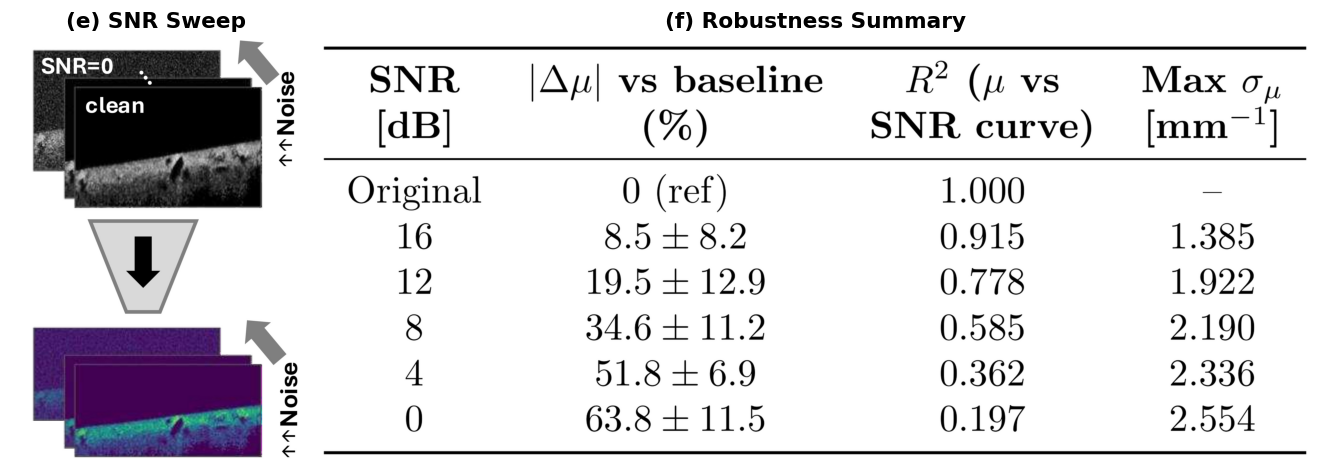

Subfigure 2 built (in-memory: (1158, 3285, 3))


In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# Subfigure 2: (e) Noise Sweep — pre-rendered design diagram
#              (f) Noise Robustness Summary — built in-notebook from LaTeX
# ══════════════════════════════════════════════════════════════════════════════
img_e = np.array(_PILImage.open(os.path.join(_panel_dir, 'panel_e_notitle.jpg')))

# ══════════════════════════════════════════════════════════════════════════════
# Panel (f) Noise Robustness Summary — built from the per-acquisition curve data
# Source: figures/data/per_acquisition_noise_curves.csv
#         (10 phantoms × 28 SNR levels — averaged across phantoms per SNR)
# Columns: SNR | |Δμ| vs baseline (%, mean ± std)
#              | R² (μ vs SNR curve)        — cohort mean of r2 column
#              | Max σ_μ                    — cohort max of sigma_mm_inv column
# Rows: Baseline, 16, 12, 8, 4, 0 dB.
# ══════════════════════════════════════════════════════════════════════════════
_curves_csv = os.path.join(DATA_DIR, 'per_acquisition_noise_curves.csv')
_dfc = pd.read_csv(_curves_csv)
_table_csv = os.path.join(DATA_DIR, 'tableB_physical_by_snr.csv')
_t = pd.read_csv(_table_csv)

_rows_to_show = ['baseline', '16', '12', '8', '4', '0']

def _row_for(snr_label):
    if snr_label == 'baseline':
        return ('Original', '0 (ref)', '1.000', '--')
    snr_num = float(snr_label)
    sub = _dfc[_dfc['snr_dB'] == snr_num]
    r2_mean    = sub['r2'].mean()
    sigma_max  = sub['sigma_mm_inv'].max()
    # delta from the cohort-aggregated table (mean ± std across 10 phantoms × seeds)
    row_t = _t[_t['snr_dB'].astype(str) == snr_label].iloc[0]
    delta = f"${float(row_t['delta_pct_mean']):.1f} \\pm {float(row_t['delta_pct_std']):.1f}$"
    return (snr_label, delta, f"{r2_mean:.3f}", f"{sigma_max:.3f}")

table_f_rows = [_row_for(s) for s in _rows_to_show]

_rows_f = ' \\\\\n'.join([' & '.join(row) for row in table_f_rows])
latex_f = (r'\begin{tabular}{c c c c}' '\n'
           r'\toprule' '\n'
           r'\textbf{SNR} & \textbf{$|\Delta\mu|$ vs baseline} & \textbf{$R^2$ ($\mu$ vs} & \textbf{Max $\sigma_{\mu}$} \\' '\n'
           r'\textbf{[dB]} & \textbf{(\%)} & \textbf{SNR curve)} & \textbf{[mm$^{-1}$]} \\' '\n'
           r'\midrule' '\n'
           + _rows_f + r' \\' '\n'
           r'\bottomrule' '\n'
           r'\end{tabular}')

img_f = _latex_table_to_img(latex_f)

print(f'panel_e: {img_e.shape}')
print(f'panel_f: {img_f.shape}')

# ── Build subfigure 2: (e) + (f) as a single image ──────────────────────────
subfig2_img = _hstack_matched([img_e, img_f], gap_px=120, target_h=TARGET_H)
print(f'subfig2_img: {subfig2_img.shape}')

fig2, ax2 = plt.subplots(1, 1, figsize=(14, 5))
ax2.imshow(subfig2_img)
ax2.axis('off')

w_e = _resize_to_height(img_e, TARGET_H).shape[1]
w_f = _resize_to_height(img_f, TARGET_H).shape[1]
w_tot2 = subfig2_img.shape[1]
e_frac = (w_e * 0.5) / w_tot2
f_frac = (w_e + 120 + w_f * 0.5) / w_tot2

ax2.text(e_frac, 1.02, '(e) SNR Sweep', transform=ax2.transAxes,
         fontsize=PANEL_FS, fontweight='bold', va='bottom', ha='center')
ax2.text(f_frac, 1.02, '(f) Robustness Summary', transform=ax2.transAxes,
         fontsize=PANEL_FS, fontweight='bold', va='bottom', ha='center')

import io as _io
_buf = _io.BytesIO()
fig2.savefig(_buf, format='png', dpi=300, bbox_inches='tight', pad_inches=0.05)
_buf.seek(0)
subfig2_img = np.array(_PILImage.open(_buf).convert('RGB'))
plt.show()
print(f'Subfigure 2 built (in-memory: {subfig2_img.shape})')

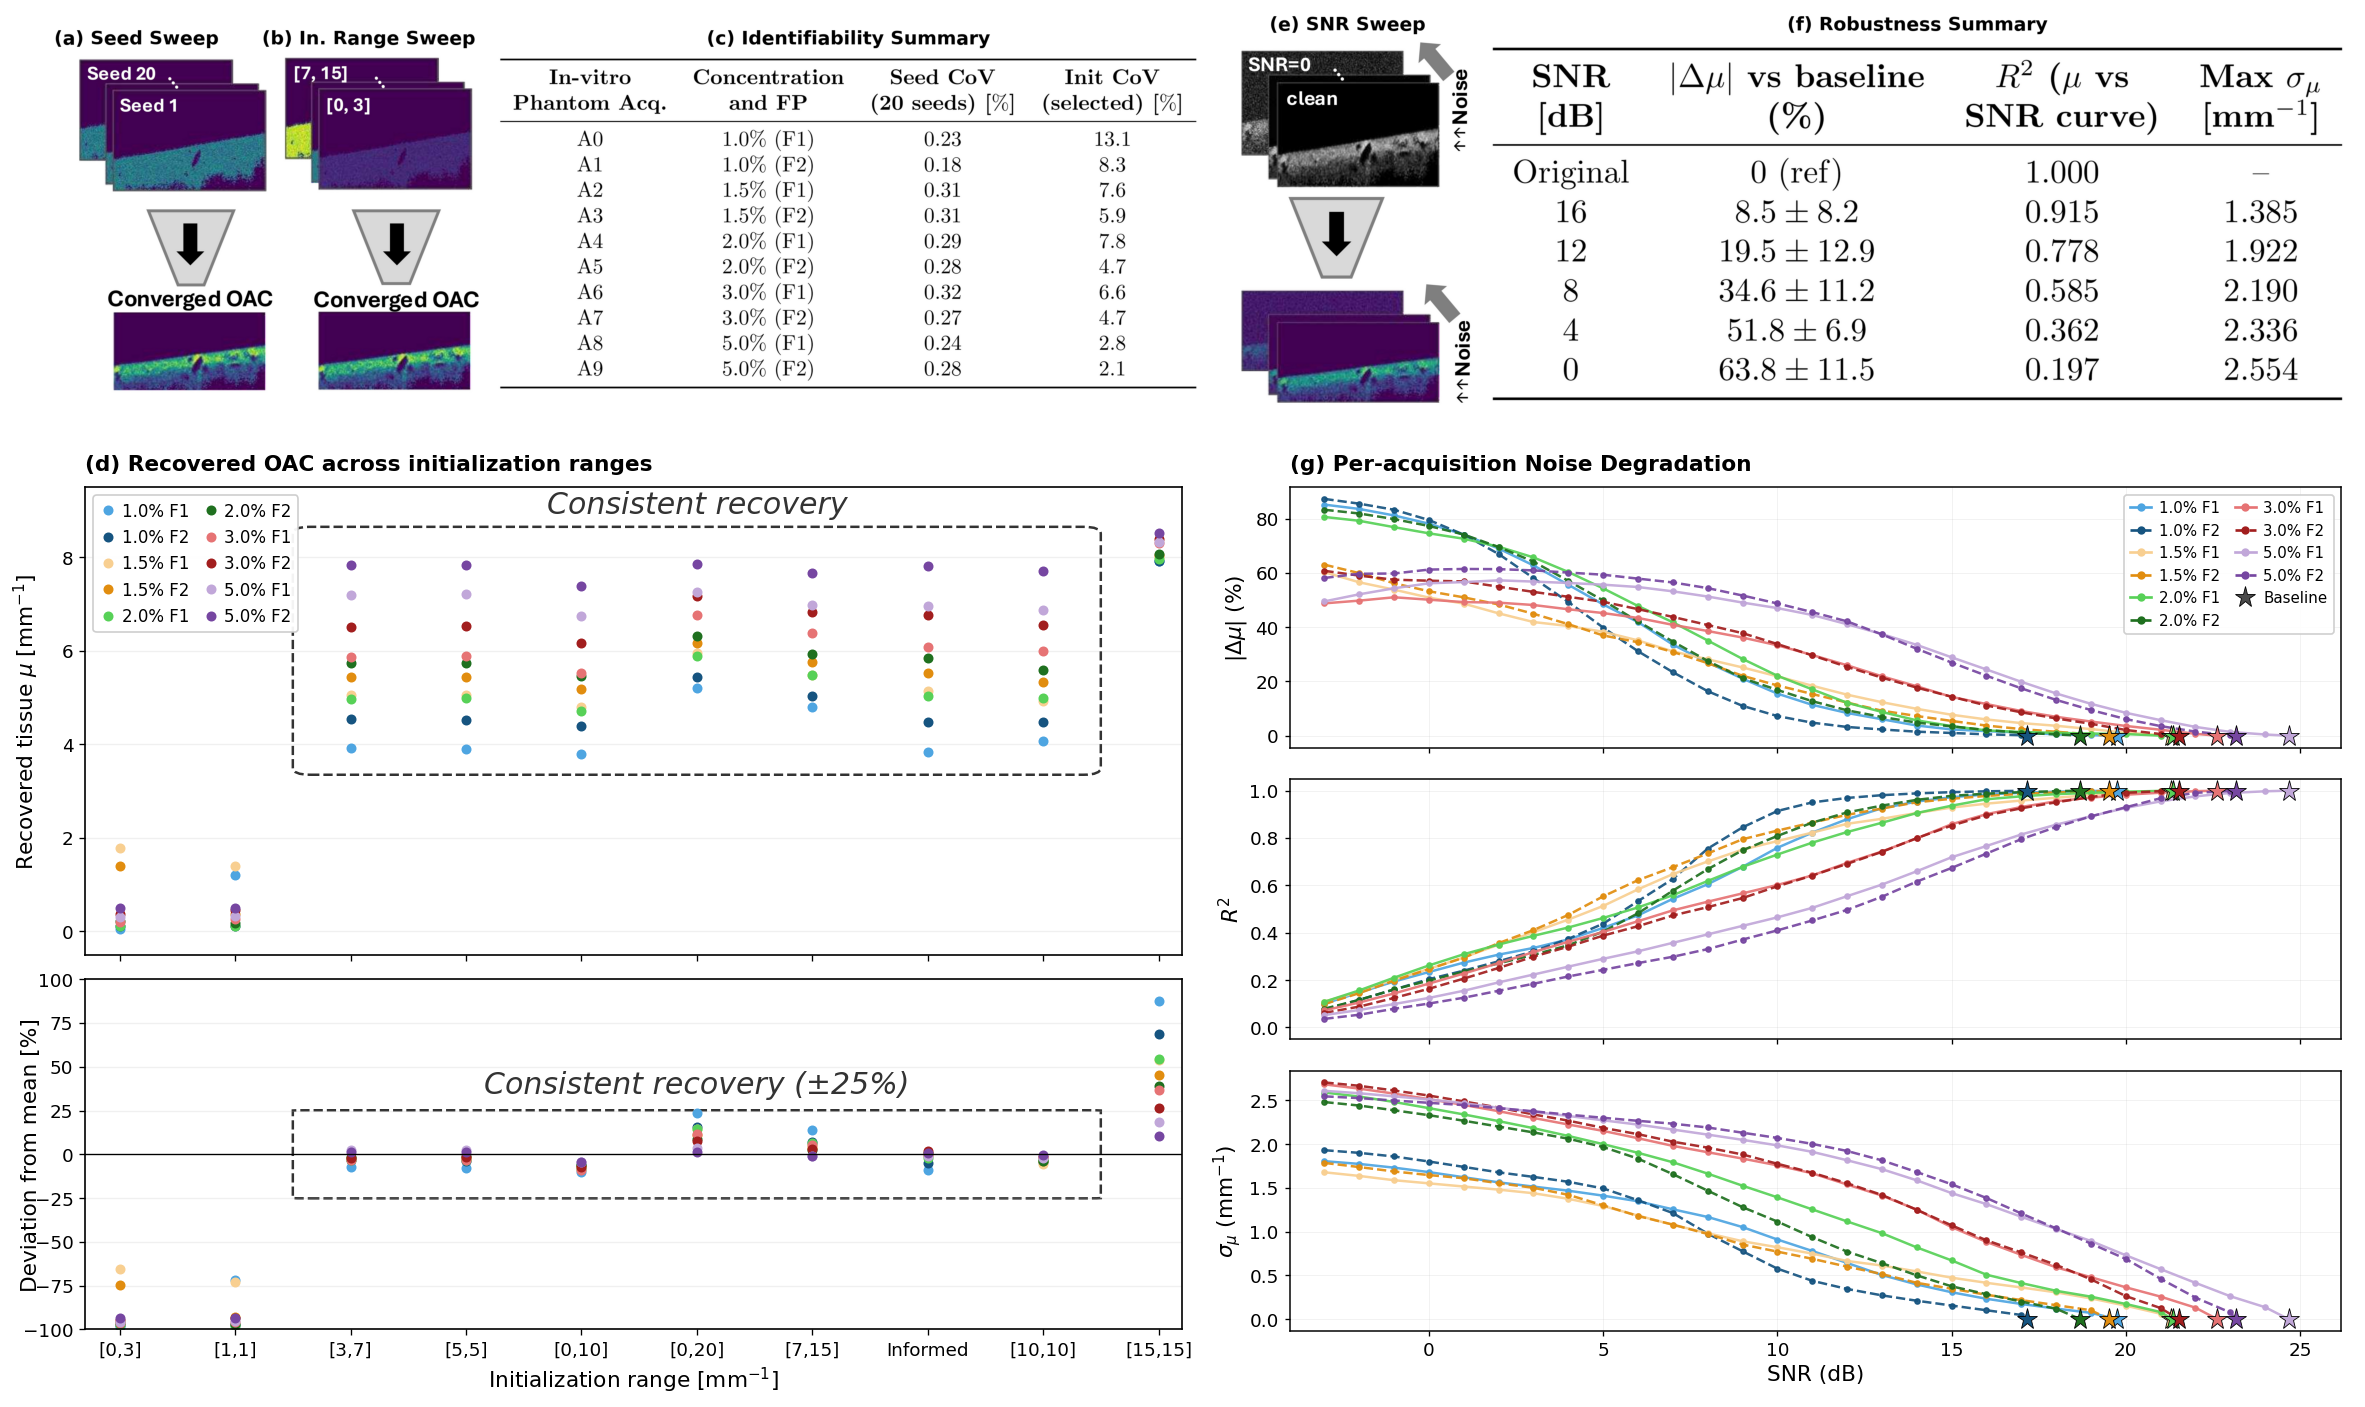

Final figure saved to /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/figures/output


In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# Final assembly: panel (g) becomes 3 horizontal 2D overlay plots — one per
# metric (|Δμ|, R², σ_μ) — with all 10 acquisitions overlaid in each.
# Panels (a)-(f) and (d) identical to v3.
# Color encoding matches v3/panel(d): F1 lighter, F2 darker per concentration.
# F1 uses solid lines, F2 uses dashed lines for additional distinction.
# Stars mark per-acquisition un-noised baseline points.
# ══════════════════════════════════════════════════════════════════════════════
from matplotlib.patches import FancyBboxPatch
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import colorsys as _colorsys
import matplotlib.colors as _mcolors

# ── Per-acquisition curves (dense: 28 SNR steps -3..24 dB per phantom) ──────
# Source CSV is produced by experiments/robustness_study.py during summarize_phase2,
# from the pre-noised TIFFs in inputs/IntralipidPhantoms_20250206_Noised/. Each row
# is (phantom_index, snr_dB, delta_pct, r2, sigma_mm_inv) — already aggregated.
_per_acq_csv = os.path.join(DATA_DIR, 'per_acquisition_noise_curves.csv')
_df_g = pd.read_csv(_per_acq_csv)

snr_g = np.sort(_df_g['snr_dB'].unique())
_phantom_order = sorted(_df_g['phantom_index'].unique())

_phantom_meta = (_df_g.groupby('phantom_index')[['label', 'baseline_snr_dB']]
                  .first().loc[_phantom_order])
labels_g   = _phantom_meta['label'].to_numpy()
baseline_g = _phantom_meta['baseline_snr_dB'].to_numpy()

def _pivot(col):
    pv = _df_g.pivot(index='phantom_index', columns='snr_dB', values=col)
    return pv.loc[_phantom_order, snr_g].to_numpy()

delta_g = _pivot('delta_pct')
r2_g    = _pivot('r2')
sigma_g = _pivot('sigma_mm_inv')

# Reuse v3's subfig2 (panel f) — assumes v3 cell ran first
sf1 = subfig1_img  # in-memory from cell 2
sf2 = subfig2_img  # in-memory from cell 3

fig_final = plt.figure(figsize=(20, 13.5))

# ── Layout (identical to v3) ─────────────────────────────────────────────────
w1 = sf1.shape[1]; w2 = sf2.shape[1]; total_w = w1 + w2
GAP_X = 0.005
LEFT, RIGHT = 0.02, 0.98
USABLE_W = RIGHT - LEFT - GAP_X
W_LEFT  = USABLE_W * w1 / total_w
W_RIGHT = USABLE_W * w2 / total_w
X_LEFT  = LEFT
X_RIGHT = LEFT + W_LEFT + GAP_X

TOP_ROW_TOP, TOP_ROW_BOTTOM = 0.98, 0.56
BOT_ROW_TOP, BOT_ROW_BOTTOM = 0.60, 0.06
H_TOP = TOP_ROW_TOP - TOP_ROW_BOTTOM
H_BOT = BOT_ROW_TOP - BOT_ROW_BOTTOM

D_GAP = 0.015
D_TOP_FRAC = 0.55
H_D_TOP = (H_BOT - D_GAP) * D_TOP_FRAC
H_D_BOT = (H_BOT - D_GAP) * (1 - D_TOP_FRAC)
Y_D_TOP = BOT_ROW_BOTTOM + H_D_BOT + D_GAP
Y_D_BOT = BOT_ROW_BOTTOM

# ── Shared color scheme (same shading helper as panel (d)) ──────────────────
def _shade(c, dl):
    r, g, b = _mcolors.to_rgb(c)
    h, l, s = _colorsys.rgb_to_hls(r, g, b)
    return _colorsys.hls_to_rgb(h, max(0.0, min(1.0, l + dl)), s)

_conc_base_d = {1.0: 'tab:blue', 1.5: '#F2A93B', 2.0: 'tab:green',
                3.0: 'tab:red', 5.0: 'tab:purple'}
conc_vals_d = sorted(_conc_base_d.keys())
conc_colors_d = {}
for _cc, _base in _conc_base_d.items():
    conc_colors_d[(_cc, 1)] = _shade(_base, +0.18)
    conc_colors_d[(_cc, 2)] = _shade(_base, -0.12)

conc_map = {0:1.0, 1:1.0, 2:1.5, 3:1.5, 4:2.0, 5:2.0, 6:3.0, 7:3.0, 8:5.0, 9:5.0}
rep_map  = {0:1, 1:2, 2:1, 3:2, 4:1, 5:2, 6:1, 7:2, 8:1, 9:2}

# ── Panel (d) data prep — identical to v3 ───────────────────────────────────
g_init = (df_init.groupby(['phantom_index','concentration','replicate','init_condition'])
          ['mu_tissue_mean'].mean().reset_index())
CONSISTENT_INITS = ['3_7','5_5','0_10','0_20','7_15','informed','10_10']
consistent_idx_start = INIT_ORDER.index('3_7')
consistent_idx_end   = INIT_ORDER.index('10_10')
box_x0 = consistent_idx_start - 0.35
box_x1 = consistent_idx_end + 0.35
phantom_mean = {}
for pidx in range(10):
    sub_consistent = g_init[(g_init['phantom_index']==pidx) &
                        (g_init['init_condition'].isin(CONSISTENT_INITS))]
    if len(sub_consistent) > 0:
        phantom_mean[pidx] = sub_consistent['mu_tissue_mean'].mean()

# ── Top row (a,b,c | e,f) ────────────────────────────────────────────────────
ax_top1 = fig_final.add_axes([X_LEFT, TOP_ROW_BOTTOM, W_LEFT, H_TOP])
ax_top1.imshow(sf1); ax_top1.axis('off')
ax_top2 = fig_final.add_axes([X_RIGHT, TOP_ROW_BOTTOM, W_RIGHT, H_TOP])
ax_top2.imshow(sf2); ax_top2.axis('off')

# ── Panel (d) scatter — identical to v3 ─────────────────────────────────────
ax_d = fig_final.add_axes([X_LEFT + 0.015, Y_D_TOP, W_LEFT - 0.025, H_D_TOP])
ax_d.set_title('(d) Recovered OAC across initialization ranges',
               fontsize=PANEL_FS, fontweight='bold', loc='left', pad=10)
ax_d.add_patch(FancyBboxPatch((box_x0, 3.5), box_x1 - box_x0, 5.0,
               boxstyle='round,pad=0.15', fill=False,
               edgecolor='#333333', linewidth=1.5, ls='--', zorder=0))
ax_d.text((consistent_idx_start + consistent_idx_end) / 2, 8.8,
          'Consistent recovery', fontsize=18, fontstyle='italic',
          color='#333333', ha='center', va='bottom', zorder=5)
for pidx in range(10):
    sub = g_init[g_init['phantom_index']==pidx].copy()
    if len(sub)==0: continue
    conc = conc_map[pidx]; rep = rep_map[pidx]
    c = conc_colors_d[(conc, rep)]
    sub['init_order'] = sub['init_condition'].map({k:i for i,k in enumerate(INIT_ORDER)})
    sub = sub.sort_values('init_order')
    ax_d.plot(sub['init_order'].values, sub['mu_tissue_mean'].values,
              marker='o', ms=5, color=c,
              ls='none', lw=0, label=f'{conc}% F{rep}')
ax_d.set_xticks(range(len(INIT_ORDER)))
ax_d.set_xticklabels([])
ax_d.set_ylabel('Recovered tissue $\\mu$ [mm$^{-1}$]', fontsize=PANEL_FS)
ax_d.set_ylim(-0.5, 9.5)
ax_d.set_xlim(-0.3, len(INIT_ORDER) - 0.8)
ax_d.tick_params(labelsize=LABEL_FS)
ax_d.grid(alpha=0.18, axis='y')
_handles, _labels_d = ax_d.get_legend_handles_labels()
_by_label = dict(zip(_labels_d, _handles))
ax_d.legend(_by_label.values(), _by_label.keys(), fontsize=LEGEND_FS + 2,
            loc='upper left', ncol=2, framealpha=0.95,
            handletextpad=0.3, columnspacing=0.8, handlelength=1.0)
ax_d.yaxis.set_label_coords(-0.04, 0.5)
for s in ax_d.spines.values():
    s.set_linewidth(1.0)

# ── Panel (d) deviation — identical to v3 ───────────────────────────────────
ax_dev = fig_final.add_axes([X_LEFT + 0.015, Y_D_BOT + 0.02,
                                W_LEFT - 0.025, H_D_BOT - 0.02])
for pidx in range(10):
    sub = g_init[g_init['phantom_index']==pidx].copy()
    if len(sub)==0 or pidx not in phantom_mean: continue
    conc = conc_map[pidx]; rep = rep_map[pidx]
    c = conc_colors_d[(conc, rep)]
    mu_ref = phantom_mean[pidx]
    sub['init_order'] = sub['init_condition'].map({k:i for i,k in enumerate(INIT_ORDER)})
    sub = sub.sort_values('init_order')
    deviation = (sub['mu_tissue_mean'].values - mu_ref) / mu_ref * 100
    ax_dev.plot(sub['init_order'].values, deviation,
                marker='o', ms=5, color=c, ls='none', lw=0)
ax_dev.axhline(0, color='black', lw=0.8, ls='-')
ax_dev.add_patch(FancyBboxPatch((box_x0, -25), box_x1 - box_x0, 50,
                 boxstyle='round,pad=0.15', fill=False,
                 edgecolor='#333333', linewidth=1.5, ls='--', zorder=0))
ax_dev.text((consistent_idx_start + consistent_idx_end) / 2, 31,
            'Consistent recovery (±25%)', fontsize=18, fontstyle='italic',
            color='#333333', ha='center', va='bottom', zorder=5)
ax_dev.set_xticks(range(len(INIT_ORDER)))
ax_dev.set_xticklabels([INIT_LABELS[k] for k in INIT_ORDER], rotation=0,
                       ha='center', fontsize=LABEL_FS)
ax_dev.set_xlabel('Initialization range [mm$^{-1}$]', fontsize=PANEL_FS)
ax_dev.set_ylabel('Deviation from mean [%]', fontsize=PANEL_FS)
ax_dev.set_ylim(-100, 100)
ax_dev.set_xlim(-0.3, len(INIT_ORDER) - 0.8)
ax_dev.tick_params(labelsize=LABEL_FS)
ax_dev.grid(alpha=0.18, axis='y')
ax_dev.yaxis.set_label_coords(-0.04, 0.5)
for s in ax_dev.spines.values():
    s.set_linewidth(1.0)

# ══════════════════════════════════════════════════════════════════════════════
# Panel (g) — 3 vertically stacked overlay panels (one per metric)
# ══════════════════════════════════════════════════════════════════════════════
G_LEFT          = X_RIGHT + 0.03
G_RIGHT         = RIGHT - 0.005
TITLE_AXIS_TOP  = Y_D_TOP + H_D_TOP
TITLE_PAD_PTS   = 10
SNR_CAPTION_Y   = 0.052

GRID_TOP    = TITLE_AXIS_TOP 
GRID_BOTTOM = SNR_CAPTION_Y + 0.027

# Title axis (aligned with panel (d) title)
ax_g_title = fig_final.add_axes(
    [G_LEFT, TITLE_AXIS_TOP - 0.001, G_RIGHT - G_LEFT, 0.001])
ax_g_title.set_title('(g) Per-acquisition Noise Degradation',
                     fontsize=PANEL_FS, fontweight='bold', loc='left',
                     pad=TITLE_PAD_PTS)
ax_g_title.axis('off')

g_gs = GridSpec(3, 1, figure=fig_final,
                left=G_LEFT, right=G_RIGHT,
                bottom=GRID_BOTTOM, top=GRID_TOP,
                hspace=0.12)

metrics_g = [
    (r'$|\Delta\mu|$ (%)',          delta_g, None,             0.0),
    (r'$R^2$',                      r2_g,    (-0.05, 1.05),    1.0),
    (r'$\sigma_{\mu}$ (mm$^{-1}$)', sigma_g, None,             0.0),
]

X_LO = float(snr_g.min()) - 1
X_HI = float(max(baseline_g)) + 1.5
STAR_MS = 13

ax_overlay = []
for mi, (ylab, data, ylim, baseline_y) in enumerate(metrics_g):
    sharex = ax_overlay[0] if mi > 0 else None
    ax = fig_final.add_subplot(g_gs[mi, 0], sharex=sharex)
    ax_overlay.append(ax)

    for pidx in range(10):
        conc = conc_map[pidx]; rep = rep_map[pidx]
        c = conc_colors_d[(conc, rep)]
        ls_style = '-' if rep == 1 else '--'
        # Insert the baseline as one more data point. Sort by x so the line
        # stays monotonic — needed now that some baselines fall inside the
        # SNR data range and would otherwise make the line trace backward.
        _xs = np.concatenate([snr_g, [baseline_g[pidx]]])
        _ys = np.concatenate([data[pidx], [baseline_y]])
        _o  = np.argsort(_xs)
        _xs = _xs[_o]; _ys = _ys[_o]
        ax.plot(_xs, _ys, ls_style, color=c, lw=1.5,
                marker='o', ms=3.0, alpha=0.92,
                label=f'{conc}% F{rep}')
        # Star overlay marking the baseline endpoint
        ax.plot(baseline_g[pidx], baseline_y, marker='*', ms=STAR_MS,
                color=c, markeredgecolor='black', markeredgewidth=0.5,
                linestyle='none', zorder=6, clip_on=False)

    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xlim(X_LO, X_HI)
    ax.set_ylabel(ylab, fontsize=PANEL_FS)
    ax.tick_params(labelsize=LABEL_FS, length=3)
    if mi < len(metrics_g) - 1:
        plt.setp(ax.get_xticklabels(), visible=False)
    ax.grid(alpha=0.18, lw=0.5)
    for s in ax.spines.values():
        s.set_linewidth(0.9)

# Centered SNR caption (aligned with panel (d) xlabel height)
fig_final.text((G_LEFT + G_RIGHT) / 2, SNR_CAPTION_Y,
                  'SNR (dB)', fontsize=PANEL_FS, ha='center', va='center')

# Single legend on the right — 10 acquisitions + baseline star
_acq_handles = []
for conc in conc_vals_d:
    for rep in (1, 2):
        c = conc_colors_d[(conc, rep)]
        ls_style = '-' if rep == 1 else '--'
        _acq_handles.append(Line2D([0], [0], color=c, ls=ls_style, lw=1.6,
                                    marker='o', ms=4, label=f'{conc}% F{rep}'))
_acq_handles.append(Line2D([0], [0], marker='*', ms=STAR_MS, color='#4a4a4a',
                            markeredgecolor='black', markeredgewidth=0.5,
                            linestyle='none', label='Baseline'))

ax_overlay[0].legend(handles=_acq_handles, loc='upper right',
                      fontsize=LABEL_FS - 2, ncol=2, frameon=True,
                      handletextpad=0.5, handlelength=1.4, borderpad=0.4,
                      columnspacing=1.0, framealpha=0.92)

# ── Save ─────────────────────────────────────────────────────────────────────
for ext in ['pdf', 'jpeg', 'svg']:
    fig_final.savefig(os.path.join(PAPER_DIR, f'figure4.{ext}'),
                         dpi=600, bbox_inches='tight')
plt.show()
print(f'Final figure saved to {PAPER_DIR}')


The seven conditions satisfy a descriptive consistency criterion: after averaging five seeds per condition, every acquisition is within ±25% of its mean across these seven conditions (maximum deviation 23.47%). This does not establish pixelwise accuracy.
The accepted manuscript Figure 4 contains earlier noise panels; preserve them for this wording-only revision using the vector PDF helper below.

In [5]:
from IPython.display import display, Image as DisplayImage
display(DisplayImage(filename=os.path.join(PAPER_DIR, 'figure4.jpeg')))
